# MLP & backpropagation in NumPy

**Guiding question:** how can we compute every gradient of a small neural network while reusing the intermediate derivatives shared by many parameters?

We first create and split the data, study the numerical example from Lecture 2, then train the same two-input, two-hidden-unit sigmoid MLP on a Playground-style XOR dataset. Every forward value and every derivative is written explicitly in NumPy: no PyTorch and no automatic differentiation.

**Content:** cached forward values, explicit parameter gradients, one numerical update, a complete XOR training loop, loss curves, decision boundaries, and held-out test results.


In [3]:
import platform
from copy import deepcopy
from functools import partial

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

SEED = 42
DTYPE = np.float32
LEARNING_RATE = 0.1
rng = np.random.default_rng(SEED)

np.set_printoptions(precision=6, suppress=True)

print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print("Device: CPU (NumPy)")
print(f"dtype: {np.dtype(DTYPE)} | seed: {SEED}")
print("First calculation: 1 example | XOR training: all training points per update")

ModuleNotFoundError: No module named 'matplotlib'

### Plotting and reporting helpers

Run this collapsed cell once. It only handles plots, parameter copies, and evaluation summaries; the forward pass, backward pass, gradient averaging, and training loop are defined visibly below. You can leave the helper source hidden.


In [ ]:
# @title Plotting and reporting helpers (run once)

def probability_on_grid(parameters, forward_fn, x_limits=(-1.8, 1.8),
                        y_limits=(-1.8, 1.8), steps=120):
    xx, yy = np.meshgrid(np.linspace(*x_limits, steps),
                         np.linspace(*y_limits, steps))
    probabilities = np.array([
        forward_fn(parameters, point)[0]
        for point in np.column_stack([xx.ravel(), yy.ravel()])
    ])
    return xx, yy, probabilities.reshape(xx.shape)


def plot_points(ax, inputs, targets, title, marker="o"):
    ax.scatter(inputs[:, 0], inputs[:, 1], c=targets,
               cmap="coolwarm", vmin=0, vmax=1, marker=marker,
               s=32, edgecolor="white", linewidth=0.4)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$",
           xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect="equal")


def plot_data_split(X_train, y_train, X_test, y_test):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    plot_points(axes[0], X_train, y_train, "Training set: 80 points")
    plot_points(axes[1], X_test, y_test, "Test set: 20 points", marker="s")
    plt.show()


def plot_boundary(ax, parameters, inputs, targets, title, forward_fn):
    xx, yy, probability = probability_on_grid(parameters, forward_fn)
    filled = ax.contourf(xx, yy, probability,
                         levels=np.linspace(0, 1, 21), cmap="coolwarm",
                         vmin=0, vmax=1, alpha=0.65)
    if probability.min() < 0.5 < probability.max():
        ax.contour(xx, yy, probability, levels=[0.5],
                   colors="#AC0033", linewidths=2)
    else:
        ax.text(0.03, 0.04, "No 0.5 contour in this window",
                transform=ax.transAxes, fontsize=9,
                bbox={"facecolor": "white", "alpha": 0.85})
    plot_points(ax, inputs, targets, title)
    return filled


def plot_decision_boundary(cases, inputs, targets, forward_fn, axes=None):
    if axes is None:
      fig, axes = plt.subplots(1, len(cases), figsize=(13, 4),
                             layout="constrained")
      # If there is only one case, axes is not an array, so we wrap it in a list to allow iteration
      if len(cases) == 1:
        axes = [axes]
    else:
      fig = axes[0].get_figure()

    print(type(axes))

    for ax, (label, parameters) in zip(axes, cases):
        filled = plot_boundary(ax, parameters, inputs, targets,
                               f"{label}", forward_fn)
    fig.colorbar(filled, ax=axes, label="P(class 1)", shrink=0.8)
    plt.show()

## 1. Dataset: noisy XOR, training and test sets

We generate four noisy clouds with alternating labels. Opposite quadrants share a class, as in the XOR pattern from TensorFlow Playground.

Each cloud contributes 20 training points and 5 test points: an 80/20 split with both classes balanced. The split is fixed before fitting. Parameter updates use only the training set; the test set is evaluated after training.


Train: X (80, 2), y (80,) | class counts [40 40]
Test:  X (20, 2), y (20,) | class counts [10 10]
Noise standard deviation: 0.28


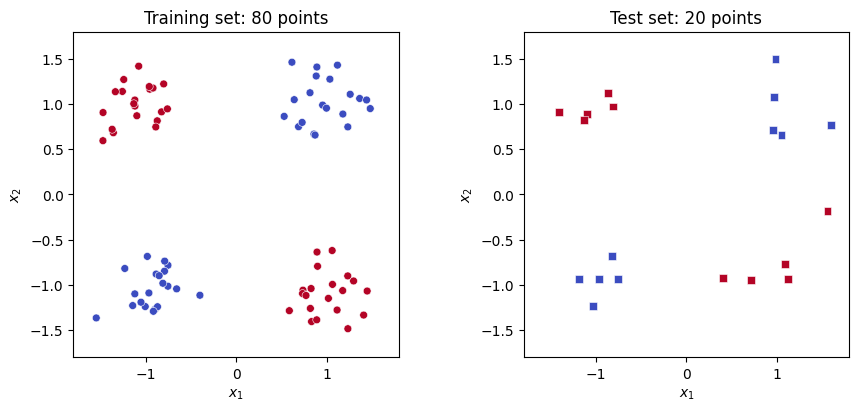

In [ ]:
points_per_cloud = 25
noise_std = 0.28
centers = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]], dtype=DTYPE)
cloud_labels = np.array([0, 1, 1, 0], dtype=DTYPE)

clouds = [
    rng.normal(center, noise_std, size=(points_per_cloud, 2))
    for center in centers
]
X_xor = np.vstack(clouds).astype(DTYPE)
y_xor = np.repeat(cloud_labels, points_per_cloud)

train_indices, test_indices = [], []
for cloud in range(4):
    indices = cloud * points_per_cloud + rng.permutation(points_per_cloud)
    train_indices.extend(indices[:20])
    test_indices.extend(indices[20:])

train_indices = rng.permutation(train_indices)
test_indices = rng.permutation(test_indices)
X_train, y_train = X_xor[train_indices], y_xor[train_indices]
X_test, y_test = X_xor[test_indices], y_xor[test_indices]

print(f"Train: X {X_train.shape}, y {y_train.shape} | class counts {np.bincount(y_train.astype(int))}")
print(f"Test:  X {X_test.shape}, y {y_test.shape} | class counts {np.bincount(y_test.astype(int))}")
print(f"Noise standard deviation: {noise_std}")
plot_data_split(X_train, y_train, X_test, y_test)


## 2. The network and its parameters

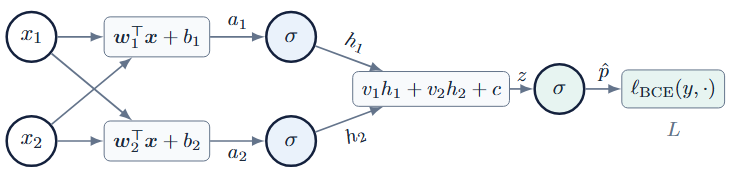

The four entries of $W$ connect the two inputs to the two hidden units. Each hidden unit has a bias; the output combines their activations with weights $v_1,v_2$ and bias $c$.

The hidden layer is

$$
\mathbf a = W\mathbf x+\mathbf b,
\qquad
\mathbf h=\sigma(\mathbf a).
$$

The output is

$$
z=\mathbf v^\top\mathbf h+c,
\qquad
\hat p=\sigma(z),
\qquad
L=-y\log\hat p-(1-y)\log(1-\hat p).
$$

$W$, $\mathbf b$, $\mathbf v$, and $c$ are trainable parameters. The values $\mathbf a$, $\mathbf h$, $z$, and $\hat p$ are computed intermediates, not parameters.


In [ ]:
#Let's define the parameters of our model

initial_params = {
    "W": np.array([[0.5, 0.5],
                   [-0.5, -0.5]], dtype=DTYPE),
    "b": np.zeros(2, dtype=DTYPE),
    "v": np.array([1.0, -1.0], dtype=DTYPE),
    "c": DTYPE(0.0),
}

initial_params


{'W': array([[ 0.5,  0.5],
        [-0.5, -0.5]], dtype=float32),
 'b': array([0., 0.], dtype=float32),
 'v': array([ 1., -1.], dtype=float32),
 'c': np.float32(0.0)}

<details>
<summary>Solution</summary>

```
x = np.array([1.0, 2.0], dtype=DTYPE)
y = DTYPE(1.0)

initial_params = {
    "W": np.array([[0.5, 0.5],
                   [-0.5, -0.5]], dtype=DTYPE),
    "b": np.zeros(2, dtype=DTYPE),
    "v": np.array([1.0, -1.0], dtype=DTYPE),
    "c": DTYPE(0.0),
}

params = deepcopy(initial_params)

parameter_count = sum(np.size(value) for value in params.values())
print(f"x shape: {x.shape} | y shape: {y.shape}")
for name, value in params.items():
    print(f"{name:>2} shape: {np.shape(value)}")
print(f"Trainable scalar parameters: {parameter_count}")
```
</details>






## 3. Forward pass: compute and cache

The backward pass will need the input, hidden activations, prediction, and target. Returning them in a cache makes the data dependencies explicit and prevents unnecessary recomputation.


In [ ]:
#Let's define the two parameter-less functions that we will need inside our MLP

def sigmoid(value):
    return 1.0 / (1.0 + np.exp(-value))

def binary_cross_entropy(target, probability):
    #target is in {0,1}
    #probability is expected to be 0<=p<=1
    return -(target * np.log(probability) + (1.0 - target) * np.log(1.0 - probability))

In [ ]:
# the forward pass computes the final loss, and caches the intermediate outputs needed for gradient computation

params = deepcopy(initial_params)

def forward(parameters, input_vector):
  a = parameters["W"]@input_vector + parameters["b"]
  h = sigmoid(a)
  z = parameters["v"]@h + parameters["c"]
  probability = sigmoid(z)

  cache = {
      "x": input_vector,
      "a": a,
      "h": h,
      "z": z,
      "p": probability
   }
  # forward pass code here
  return probability, cache

x = np.asarray([0,0])
initial_prob, cache = forward(params, x)

initial_prob
binary_cross_entropy(1,initial_prob)
print(f"x     = {cache['x']}")
print(f"a     = {cache['a']}")
print(f"h     = {cache['h']}")
print(f"z     = {cache['z']:.6f}")
print(f"p_hat = {cache['p']:.6f}")
# print(f"loss  = {initial_loss:.6f}")


x     = [0 0]
a     = [0. 0.]
h     = [0.5 0.5]
z     = 0.000000
p_hat = 0.500000


<details>
<summary>Solution</summary>

```
def forward(parameters, input_vector):
    a = parameters["W"] @ input_vector + parameters["b"]
    h = sigmoid(a)
    z = parameters["v"] @ h + parameters["c"]
    probability = sigmoid(z)
    
    #As we have seen, these values might be helpful for the gradient computation, so we save them for later
    cache = {
        "x": input_vector,
        "a": a,
        "h": h,
        "z": z,
        "p": probability,
    }
    return probability, cache


initial_prob, cache = forward(params, x)

print(f"x     = {cache['x']}")
print(f"a     = {cache['a']}")
print(f"h     = {cache['h']}")
print(f"z     = {cache['z']:.6f}")
print(f"p_hat = {cache['p']:.6f}")
print(f"loss  = {initial_loss:.6f}")

### Different initializations, different predictions

Evaluate the same forward function with the previous parameters and two random initializations. These are untrained networks, not successive gradient steps. Compare their probabilities and boundaries on the training set; we do not use test scores to choose an initialization.


In [ ]:
#test your model with different initializazions

<class 'numpy.ndarray'>


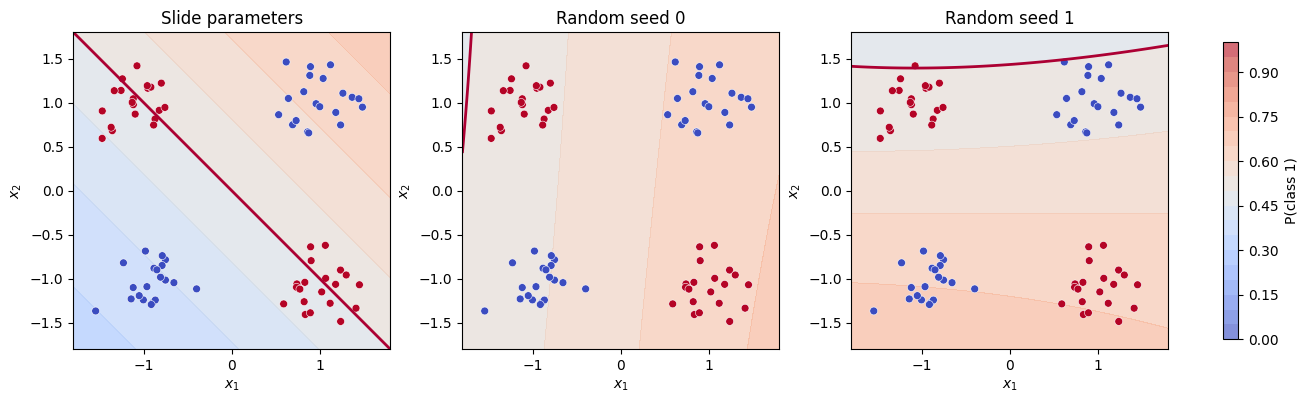

In [ ]:
initialization_cases = [("Slide parameters", initial_params)]

for i in range(2):
    init_rng = np.random.default_rng(i)
    random_params = {
        "W": init_rng.normal(size=(2, 2)),
        "b": init_rng.normal(size=2),
        "v": init_rng.normal(size=2),
        "c": DTYPE(init_rng.normal()),
    }
    initialization_cases.append((f"Random seed {i}", random_params))

#add random initializations here

plot_decision_boundary(initialization_cases, X_train, y_train, forward)

<details>
<summary>Solution</summary>

```
initialization_cases = [("Slide parameters", initial_params)]
for seed in (0, 1):
    init_rng = np.random.default_rng(seed)
    random_params = {
        "W": init_rng.normal(size=(2, 2)),
        "b": init_rng.normal(size=2),
        "v": init_rng.normal(size=2),
        "c": DTYPE(init_rng.normal()),
    }
    initialization_cases.append((f"Random seed {seed}", random_params))

plot_initializations(initialization_cases, X_train, y_train)


## 4. Backward pass: reuse shared derivatives

Start at the output:

$$
\delta_z=\frac{\partial L}{\partial z}=\hat p-y.
$$

Reuse $\delta_z$ for the output parameters and propagate it to both hidden units:

$$
\nabla_{\mathbf v}L=\delta_z\mathbf h,
\qquad
\boldsymbol\delta_a
=\delta_z\mathbf v\odot\mathbf h\odot(1-\mathbf h).
$$

Finally,

$$
\nabla_WL=\boldsymbol\delta_a\mathbf x^\top,
\qquad
\nabla_{\mathbf b}L=\boldsymbol\delta_a,
\qquad
\nabla_c L=\delta_z.
$$


In [ ]:
#The backword step computes the actual gradient for all model's parameters

def backward(parameters, forward_cache, target):
  #define the gradients computation here
  input_vector = forward_cache["x"]
  h = forward_cache["h"]
  p = forward_cache["p"]

  delta_z = p - target
  grad_v = delta_z * h
  grad_c = delta_z

  delta_h = delta_z * parameters["v"]
  delta_a = delta_h * h * (1.0 - h)

  grad_W = np.outer(delta_a, input_vector) #here for w_1 we compute w_1 * delta_a1, and similarly for w_2
  grad_b = delta_a

  gradients = {"W": grad_W, "b": grad_b, "v": grad_v, "c": grad_c}
  backward_values = {"delta_z": delta_z, "delta_h": delta_h, "delta_a": delta_a}

  return gradients, backward_values

y = 0
grads, backward_values = backward(params, cache, y)
grads

{'W': array([[ 0.,  0.],
        [-0., -0.]]),
 'b': array([ 0.125, -0.125]),
 'v': array([0.25, 0.25]),
 'c': np.float64(0.5)}

<details>
<summary>Solution</summary>

```
def backward(parameters, forward_cache, target):
    input_vector = forward_cache["x"]
    h = forward_cache["h"]
    p = forward_cache["p"]

    delta_z = p - target
    grad_v = delta_z * h
    grad_c = delta_z

    delta_h = delta_z * parameters["v"]
    delta_a = delta_h * h * (1.0 - h)
    grad_W = np.outer(delta_a, input_vector) #here for w_1 we compute w_1 * delta_a1, and similarly for w_2
    grad_b = delta_a

    gradients = {"W": grad_W, "b": grad_b, "v": grad_v, "c": grad_c}
    backward_values = {"delta_z": delta_z, "delta_h": delta_h, "delta_a": delta_a}
    return gradients, backward_values


grads, backward_values = backward(params, cache, y)

## 5. One simultaneous gradient-descent update

All gradients must be computed at the same parameter values. Only then do we update every parameter using

$$
\theta_{t+1}=\theta_t-\eta\nabla_\theta L(\theta_t).
$$

The function below changes the supplied parameter dictionary in place. The saved `initial_params` stays unchanged, so the training experiment can restart from the original slide values.


In [ ]:
LEARNING_RATE

0.1

In [ ]:
#Define and apply one gradint descent step, and observe how parameters and loss change

def gradient_step(parameters, gradients, learning_rate):
  # apply the descent step inplace to the model parameters
  for name in parameters:
    parameters[name] -= learning_rate * gradients[name]

y= 1
LEARNING_RATE = 0.1
print("Prob before: ",forward(params, x))
print("Loss before: ",binary_cross_entropy(y,forward(params, x)[0]))

grads, backward_values = backward(params, cache, y)
gradient_step(params, grads, LEARNING_RATE)
print("Prob after: ",forward(params, x))
print("Loss after: ",binary_cross_entropy(y,forward(params, x)[0]))

Prob before:  (np.float64(0.5), {'x': array([0, 0]), 'a': array([0., 0.]), 'h': array([0.5, 0.5]), 'z': np.float64(0.0), 'p': np.float64(0.5)})
Loss before:  0.6931471805599453
Prob after:  (np.float64(0.520301306613559), {'x': array([0, 0]), 'a': array([ 0.0125, -0.0125]), 'h': array([0.503125, 0.496875]), 'z': np.float64(0.08124989487233389), 'p': np.float64(0.520301306613559)})
Loss after:  0.6533471994194592


<details>
<summary>Solution</summary>

```
def gradient_step(parameters, gradients, learning_rate):
    for name in parameters:
        parameters[name] -= learning_rate * gradients[name]

print("Loss before: ",binary_cross_entropy(y,forward(params, x)[0]))
gradient_step(params, grads, LEARNING_RATE)
print("Loss after: ",binary_cross_entropy(y,forward(params, x)[0]))


## 6. Reuse the same functions on the training set

Each point is still one input $\mathbf x_i\in\mathbb R^2$. For each training point, call the existing forward and backward functions. Sum their loss and gradient contributions, then divide by the number of training examples:

$$
\nabla_\theta J=\frac{1}{n_{\mathrm{train}}}\sum_{i=1}^{n_{\mathrm{train}}}g_i.
$$

All contributions are computed at the same parameters. There is no new backward rule for XOR, and no test example enters this average.


In [ ]:
params

{'W': array([[ 0.5,  0.5],
        [-0.5, -0.5]], dtype=float32),
 'b': array([ 0.0125, -0.0125], dtype=float32),
 'v': array([ 1.025, -0.975], dtype=float32),
 'c': np.float64(0.05)}

In [ ]:
#Accumulate the loss and the gradient over al the training samples

def batch_gradients(forward, backward, parameters, inputs, targets):
  ####
  loss_sum = 0
  gradient_means = {name: np.zeros_like(value)
                   for name, value in parameters.items()}
  for x,y in zip(inputs, targets):
    probability, sample_cache = forward(parameters, x)
    loss = binary_cross_entropy(y, forward(parameters, x)[0])
    gradients, _ = backward(parameters, sample_cache, y)

    loss_sum += loss
    for name, value in parameters.items():
        gradient_means[name] += gradients[name]

  mean_loss = loss_sum/len(inputs)
  for name, value in parameters.items():
        gradient_means[name] /= len(inputs)

  return mean_loss, gradient_means

In [ ]:
batch_gradients(forward, backward, params, np.random.randn(6,2), np.ones(6))

(np.float64(0.651468725468129),
 {'W': array([[-0.045234,  0.069667],
         [ 0.043028, -0.066269]], dtype=float32),
  'b': array([-0.095039,  0.090403], dtype=float32),
  'v': array([-0.22284 , -0.243772], dtype=float32),
  'c': array(-0.466613)})

<details>
<summary>Solution</summary>

```
def batch_gradients(forward, backward, parameters, inputs, targets):
    loss_sum = 0.0
    gradient_sums = {name: np.zeros_like(value)
                     for name, value in parameters.items()}

    for point, target in zip(inputs, targets):
        probability, sample_cache = forward(parameters, point)
        
        loss = binary_cross_entropy(target, forward(parameters, point)[0])

        gradients, _ = backward(parameters, sample_cache, target)

        #accumulate loss and gradients among all samples
        loss_sum += loss
        for name in parameters:
            gradient_sums[name] += gradients[name]

    count = len(targets)
    mean_gradients = {name: total / count
                      for name, total in gradient_sums.items()}
    return loss_sum / count, mean_gradients

## 7. The training loop

Each iteration computes the mean training gradient, then updates the parameters once. We restart from the original slide parameters, not the parameters already changed in the single-example demonstration.

The learning rate and 2,000-update budget are fixed in advance. Since every update uses all 80 training examples, this run performs 2,000 epochs and 160,000 training-example presentations. Evaluation does not update parameters and is not counted in that training budget.


In [ ]:
# X_xor
# y_xor

In [ ]:
#now define a full training loop, for 2000 iterations with a learning rate of 0.5

model_batch_gradients = partial(batch_gradients, forward, backward)
def train_mlp(model_batch_gradients, parameters, inputs, targets, updates, learning_rate):
    ###
    losses = []
    for i in range(updates):
      loss, gradients = model_batch_gradients(parameters, inputs, targets)
      losses.append(loss)
      gradient_step(parameters, gradients, learning_rate)

    return np.array(losses)

XOR_UPDATES = 2_000
XOR_LEARNING_RATE = 0.5
trained_params = deepcopy(initial_params)
xor_losses = train_mlp(
    model_batch_gradients, trained_params, X_train, y_train, XOR_UPDATES, XOR_LEARNING_RATE
)

print(f"Updates / epochs: {XOR_UPDATES:,}")
print(f"Training-example presentations: {XOR_UPDATES * len(X_train):,}")
print(f"Training BCE: {xor_losses[0]:.6f} -> {xor_losses[-1]:.6f}")


Updates / epochs: 2,000
Training-example presentations: 160,000
Training BCE: 0.714002 -> 0.018191


<details>
<summary>Solution</summary>

```
model_batch_gradients = partial(batch_gradients, forward, backward)
def train_mlp(model_batch_gradients, parameters, inputs, targets, updates, learning_rate):
    losses = []
    for _ in range(updates):
        loss, gradients = model_batch_gradients(parameters, inputs, targets)
        losses.append(loss)
        gradient_step(parameters, gradients, learning_rate)

    final_loss, _ = model_batch_gradients(parameters, inputs, targets)
    losses.append(final_loss)
    return np.array(losses)
    
XOR_UPDATES = 2_000
XOR_LEARNING_RATE = 0.5
trained_params = deepcopy(initial_params)
xor_losses = train_mlp(
    model_batch_gradients, trained_params, X_train, y_train, XOR_UPDATES, XOR_LEARNING_RATE
)

print(f"Updates / epochs: {XOR_UPDATES:,}")
print(f"Training-example presentations: {XOR_UPDATES * len(X_train):,}")
print(f"Training BCE: {xor_losses[0]:.6f} -> {xor_losses[-1]:.6f}")

### Training behavior and held-out evaluation

The curve contains the initial loss and the loss after each update: 2,001 measurements, but only 2,000 updates. The boundary panels show training points. We now evaluate the fixed trained model on the held-out test set without changing its parameters.

A good result on these 20 test points is evidence for this particular split and distribution, not a guarantee for arbitrary inputs or every random seed.


<class 'numpy.ndarray'>


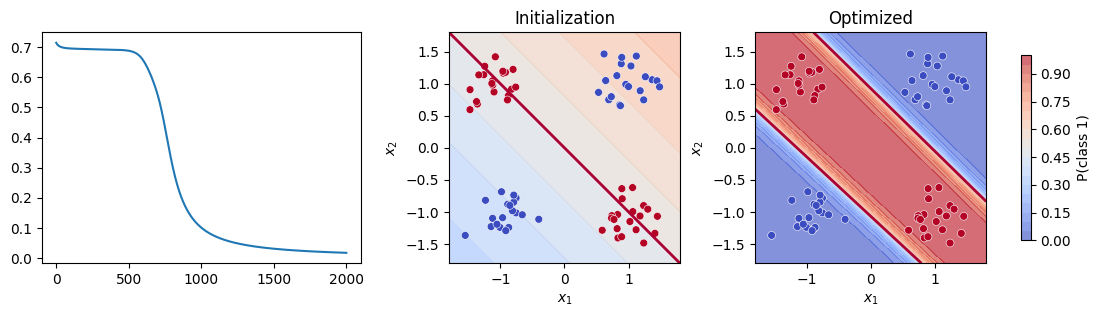

In [ ]:
#Plot side by side loss behaviour and decision boundary
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xor_losses)
plot_decision_boundary([("Initialization", initial_params),("Optimized", trained_params)], X_train, y_train, forward, axes[1:])


In [ ]:
# Extract probabilities and calculate BCE using NumPy and scikit-learn
train_probs = np.array([forward(trained_params, x)[0] for x in X_train])
test_probs = np.array([forward(trained_params, x)[0] for x in X_test])

# Convert probabilities to boolean predictions
train_preds = train_probs >= 0.5
test_preds = test_probs >= 0.5

# Calculate accuracy using scikit-learn
train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

# Calculate the mean Binary Cross-Entropy loss explicitly
train_loss = np.mean([binary_cross_entropy(y, p) for y, p in zip(y_train, train_probs)])
test_loss = np.mean([binary_cross_entropy(y, p) for y, p in zip(y_test, test_probs)])

# Explicitly print the final results
print(f"{'Split':<10} {'Mean BCE':>10} {'Accuracy':>10} {'Examples':>10}")
print(f"{'Train':<10} {train_loss:>10.6f} {train_acc:>10.3f} {len(y_train):>10}")
print(f"{'Test':<10} {test_loss:>10.6f} {test_acc:>10.3f} {len(y_test):>10}")

Split        Mean BCE   Accuracy   Examples
Train        0.018175      1.000         80
Test         0.181356      0.950         20


## 8. Failure case: all-zero initialization on balanced data

The previous run fits the XOR clouds, but optimization also depends on the starting point. If every weight and bias is initialized to zero, both hidden units compute the same value and receive the same information. Predict what the training curve will do before running the cell.


In [ ]:
#Try to run your training loop from different initialization (including all-zeros). Observe if the training converges to a good solution.

<details>
<summary>Solution</summary>

```
zero_params = {name: np.zeros_like(value)
               for name, value in initial_params.items()}
init_params = deepcopy(zero_params)
zero_losses = train_mlp(
    model_batch_gradients, zero_params, X_train, y_train, XOR_UPDATES, XOR_LEARNING_RATE
)

plot_decision_boundary([("Zero-init", zero_params)], X_train, y_train, forward)


# Explicitly extract probabilities and calculate BCE / accuracy using NumPy and scikit-learn
zero_train_probs = np.array([forward(zero_params, x)[0] for x in X_train])
zero_test_probs = np.array([forward(zero_params, x)[0] for x in X_test])

zero_train_preds = zero_train_probs >= 0.5
zero_test_preds = zero_test_probs >= 0.5

zero_train_acc = accuracy_score(y_train, zero_train_preds)
zero_test_acc = accuracy_score(y_test, zero_test_preds)

zero_train_loss = np.mean([binary_cross_entropy(y, p) for y, p in zip(y_train, zero_train_probs)])
zero_test_loss = np.mean([binary_cross_entropy(y, p) for y, p in zip(y_test, zero_test_probs)])

print(f"Same budget: {XOR_UPDATES:,} updates / epochs, {XOR_UPDATES * len(X_train):,} training-example presentations")
print(f"Zero-init training BCE: {zero_losses[0]:.6f} -> {zero_losses[-1]:.6f}")
print(f"Zero-init training accuracy: {zero_train_acc:.3f}")

print(f"\n{'Split':<10} {'Mean BCE':>10} {'Accuracy':>10} {'Examples':>10}")
print(f"{'Train':<10} {zero_train_loss:>10.6f} {zero_train_acc:>10.3f} {len(y_train):>10}")
print(f"{'Test':<10} {zero_test_loss:>10.6f} {zero_test_acc:>10.3f} {len(y_test):>10}")
```
</details>